# 🔬 Semi-Supervised Learning for Metallicity (Materials Project)
## Demonstrating SSL with limited labeled data

---

### 🎯 Objective
Train with only **1,000 labeled compositions** and compare a supervised baseline with five semi-supervised methods (Label Propagation, Label Spreading, Self-Training, Co-Training, Cluster-then-Label) and self-supervised pre-training, while the unlabeled pool grows from 1,000 to 100,000 compositions.

The full sweep (3 seeds × 4 pool sizes × 2 unlabeled-pool settings, Optuna tuning) is run by `pipeline/run_ssl_experiments.py`; this notebook loads its results and re-runs every method once live.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
TASK = "metallicity"
PRED = ROOT / "data" / "predictions" / TASK
from IPython.display import Image, display

In [2]:
print("=" * 100); print("STEP 1: LOADING EXPERIMENT RESULTS"); print("=" * 100)
summ = {p: json.loads((PRED / p / f'ssl_summary_{TASK}.json').read_text()) for p in ('indist', 'gnome') if (PRED / p / f'ssl_summary_{TASK}.json').exists()}
res = {p: pd.read_csv(PRED / p / f'ssl_results_{TASK}.csv') for p in summ}
for p, s in summ.items():
    print(p, json.dumps(s['training_setup'], indent=1))

STEP 1: LOADING EXPERIMENT RESULTS
indist {
 "n_labeled_compositions_total": 77432,
 "n_train_pool": 61945,
 "n_test": 15487,
 "n_test_evaluated": 15487,
 "labeled_budget": 1000,
 "unlabeled_pool": "same database, labels hidden",
 "unlabeled_pool_size": 60945,
 "unlabeled_sizes_tested": [
  1000,
  5000,
  25000,
  60945
 ],
 "seeds": 3,
 "n_features": 142,
 "co_training_views": [
  132,
  10
 ],
 "stratified_sampling": true,
 "metric_used_for_selection": "Composite Score (mean of F1 & ROC-AUC), averaged over seeds"
}
gnome {
 "n_labeled_compositions_total": 77432,
 "n_train_pool": 61945,
 "n_test": 15487,
 "n_test_evaluated": 15487,
 "labeled_budget": 1000,
 "unlabeled_pool": "GNoME",
 "unlabeled_pool_size": 554047,
 "unlabeled_sizes_tested": [
  1000,
  5000,
  25000,
  100000
 ],
 "seeds": 3,
 "n_features": 142,
 "co_training_views": [
  132,
  10
 ],
 "stratified_sampling": true,
 "metric_used_for_selection": "Composite Score (mean of F1 & ROC-AUC), averaged over seeds"
}


In [3]:
print("STEP 2-3: BASELINE MODEL ZOO (supervised, 1,000 labels, mean over 3 seeds)")
r = res['indist']
zoo = r[r.Method == 'Baseline'].groupby('Config')[['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite_Score']].agg(['mean', 'std'])
zoo.sort_values(('Composite_Score', 'mean'), ascending=False).round(4)

STEP 2-3: BASELINE MODEL ZOO (supervised, 1,000 labels, mean over 3 seeds)


Accuracy         Precision          Recall         F1-Score         ROC-AUC         Composite_Score        
                         mean     std      mean     std    mean     std     mean     std    mean     std            mean     std
Config                                                                                                                          
LightGBM (tuned)       0.8499  0.0013    0.8755  0.0041  0.7987  0.0019   0.8354  0.0008  0.9152  0.0007          0.8753  0.0008
XGBoost (default)      0.8497  0.0018    0.8730  0.0038  0.8012  0.0062   0.8356  0.0025  0.9149  0.0016          0.8752  0.0020
LightGBM (default)     0.8489  0.0035    0.8720  0.0039  0.8006  0.0040   0.8348  0.0038  0.9142  0.0012          0.8745  0.0024
RF (default)           0.8510  0.0023    0.8934  0.0028  0.7804  0.0032   0.8331  0.0026  0.9141  0.0006          0.8736  0.0014
XGBoost (tuned)        0.8475  0.0024    0.8672  0.0036  0.8029  0.0014   0.8338  0.0024  0.9128  0.0018          0.8733  0.0021
ExtraTrees (default)   0.8479  0.0026    0.8851  0.0055  0.7825  0.0019   0.8306  0.0024  0.9100  0.0017          0.8703  0.0016
MLP (default)          0.8341  0.0081    0.8844  0.0254  0.7509  0.0213   0.8118  0.0088  0.9008  0.0042          0.8563  0.0065
LogReg (default)       0.8304  0.0021    0.8654  0.0170  0.7632  0.0158   0.8109  0.0021  0.8995  0.0019          0.8552  0.0020
kNN (default)          0.8355  0.0022    0.8984  0.0044  0.7385  0.0077   0.8106  0.0035  0.8983  0.0012          0.8544  0.0021

In [4]:
print("STEP 4: OPTUNA HYPER-PARAMETER SEARCH (25 trials, 5-fold CV)")
pd.DataFrame({'CV composite': summ['indist']['optuna_cv_scores'], 'best params': {k: str(v) for k, v in summ['indist']['tuned_params'].items()}})

STEP 4: OPTUNA HYPER-PARAMETER SEARCH (25 trials, 5-fold CV)


,CV composite,best params
XGBoost,0.852992,"{'n_estimators': 400, 'max_depth': 8, 'learnin..."
LightGBM,0.857586,"{'n_estimators': 400, 'num_leaves': 26, 'learn..."


In [5]:
print("STEP 4b: SELF-SUPERVISED PRE-TRAINING (masked autoencoder on 554k GNoME)")
r[r.Method == 'Self-Supervised (AE)'].groupby('Config')[['F1-Score', 'ROC-AUC', 'Composite_Score']].agg(['mean', 'std']).round(4)

STEP 4b: SELF-SUPERVISED PRE-TRAINING (masked autoencoder on 554k GNoME)


F1-Score         ROC-AUC         Composite_Score        
                                 mean     std    mean     std            mean     std
Config                                                                               
LightGBM* on ae features       0.8168  0.0017  0.9012  0.0028          0.8590  0.0021
LightGBM* on raw+ae features   0.8353  0.0021  0.9142  0.0011          0.8747  0.0015

In [6]:
print("STEP 5-8: SEMI-SUPERVISED SWEEP – mean composite per pool size")
for p, r_ in res.items():
    print(f'--- unlabeled pool: {p}')
    ssl = r_[~r_.Method.isin(['Baseline', 'Self-Supervised (AE)'])]
    display(ssl.pivot_table(index=['Method', 'Config'], columns='N_Unlabeled', values='Composite_Score', aggfunc='mean').round(4))

STEP 5-8: SEMI-SUPERVISED SWEEP – mean composite per pool size
--- unlabeled pool: indist


N_Unlabeled                                                  1000    5000    25000   60945
Method             Config                                                                 
Cluster-then-Label CtL LightGBM* k=100 purity=0.8           0.8741  0.8701  0.8589  0.8569
                   CtL LightGBM* k=100 purity=0.8 [raw+AE]  0.8728  0.8671  0.8627  0.8574
Co-Training        CT LightGBM* tau=0.85                    0.8619  0.8525  0.8457  0.8424
                   CT RF tau=0.85                           0.8576  0.8455     NaN     NaN
Label Propagation  LP knn k=10                              0.8475  0.8396  0.8294  0.8193
                   LP rbf                                   0.8304  0.8269     NaN     NaN
Label Spreading    LS knn k=10 alpha=0.2                    0.8470  0.8372  0.8240  0.8133
                   LS knn k=10 alpha=0.2 [AE space]         0.8404  0.8333  0.8187  0.8019
                   LS knn k=10 alpha=0.8                    0.8480  0.8418  0.8310  0.8202
                   LS rbf alpha=0.2                         0.8296  0.8249     NaN     NaN
Self-Training      ST LightGBM* tau=0.75                    0.8745  0.8726     NaN     NaN
                   ST LightGBM* tau=0.9                     0.8754  0.8715  0.8689  0.8673
                   ST LightGBM* tau=0.9 [raw+AE]            0.8732  0.8701     NaN     NaN
                   ST RF tau=0.75                           0.8690  0.8552     NaN     NaN

--- unlabeled pool: gnome


N_Unlabeled                                                 1000    5000    25000   100000
Method             Config                                                                 
Cluster-then-Label CtL LightGBM* k=100 purity=0.8           0.8725  0.8666  0.8561  0.8477
                   CtL LightGBM* k=100 purity=0.8 [raw+AE]  0.8726  0.8670  0.8582  0.8489
Co-Training        CT LightGBM* tau=0.85                    0.8560  0.8054  0.7675  0.7516
                   CT RF tau=0.85                           0.8613  0.8409     NaN     NaN
Label Propagation  LP knn k=10                              0.6924  0.6734  0.6469  0.6394
                   LP rbf                                   0.7447  0.7510     NaN     NaN
Label Spreading    LS knn k=10 alpha=0.2                    0.6736  0.6572  0.6773  0.7761
                   LS knn k=10 alpha=0.2 [AE space]         0.6688  0.6713  0.6922  0.7884
                   LS knn k=10 alpha=0.8                    0.6644  0.6596  0.6793  0.6815
                   LS rbf alpha=0.2                         0.7405  0.7406     NaN     NaN
Self-Training      ST LightGBM* tau=0.75                    0.8695  0.8619     NaN     NaN
                   ST LightGBM* tau=0.9                     0.8703  0.8607  0.8512  0.8454
                   ST LightGBM* tau=0.9 [raw+AE]            0.8709  0.8599     NaN     NaN
                   ST RF tau=0.75                           0.8698  0.8585     NaN     NaN

In [7]:
print("STEP 9: COMPREHENSIVE RESULTS COMPARISON (best configuration per method)")
for p, s in summ.items():
    print(f'--- unlabeled pool: {p}')
    b = pd.DataFrame(s['best_per_method'])[['Method', 'Model_Config', 'Composite_Score_mean', 'Composite_Score_std', 'F1-Score_mean', 'ROC-AUC_mean', 'Accuracy_mean']]
    display(b.round(4))
    print('SSL vs best baseline: %+.2f %%' % s['ssl_improvement_over_best_baseline_pct'])

STEP 9: COMPREHENSIVE RESULTS COMPARISON (best configuration per method)
--- unlabeled pool: indist


,Method,Model_Config,Composite_Score_mean,Composite_Score_std,F1-Score_mean,ROC-AUC_mean,Accuracy_mean
0,Self-Training,ST LightGBM* tau=0.9 | n=1000,0.8754,0.0005,0.8361,0.9147,0.8517
1,Baseline,LightGBM (tuned),0.8753,0.0008,0.8354,0.9152,0.8499
2,Self-Supervised (AE),LightGBM* on raw+ae features,0.8747,0.0015,0.8353,0.9142,0.8510
3,Cluster-then-Label,CtL LightGBM* k=100 purity=0.8 | n=1000,0.8741,0.0013,0.8328,0.9154,0.8503
4,Co-Training,CT LightGBM* tau=0.85 | n=1000,0.8619,0.0003,0.8194,0.9044,0.8402
5,Label Spreading,LS knn k=10 alpha=0.8 | n=1000,0.8480,0.0012,0.8053,0.8906,0.8173
6,Label Propagation,LP knn k=10 | n=1000,0.8475,0.0018,0.8057,0.8893,0.8173


SSL vs best baseline: +0.01 %
--- unlabeled pool: gnome


,Method,Model_Config,Composite_Score_mean,Composite_Score_std,F1-Score_mean,ROC-AUC_mean,Accuracy_mean
0,Baseline,LightGBM (tuned),0.8753,0.0008,0.8354,0.9152,0.8499
1,Self-Supervised (AE),LightGBM* on raw+ae features,0.8747,0.0015,0.8353,0.9142,0.8510
2,Cluster-then-Label,CtL LightGBM* k=100 purity=0.8 [raw+AE] | n=1000,0.8726,0.0009,0.8315,0.9137,0.8515
3,Self-Training,ST LightGBM* tau=0.9 [raw+AE] | n=1000,0.8709,0.0007,0.8291,0.9127,0.8506
4,Co-Training,CT RF tau=0.85 | n=1000,0.8613,0.0006,0.8193,0.9032,0.8403
5,Label Spreading,LS knn k=10 alpha=0.2 [AE space] | n=100000,0.7884,0.0045,0.7351,0.8416,0.7796
6,Label Propagation,LP rbf | n=5000,0.7510,0.0049,0.6305,0.8715,0.7378


SSL vs best baseline: -0.30 %


STEP 10: LEARNING CURVES


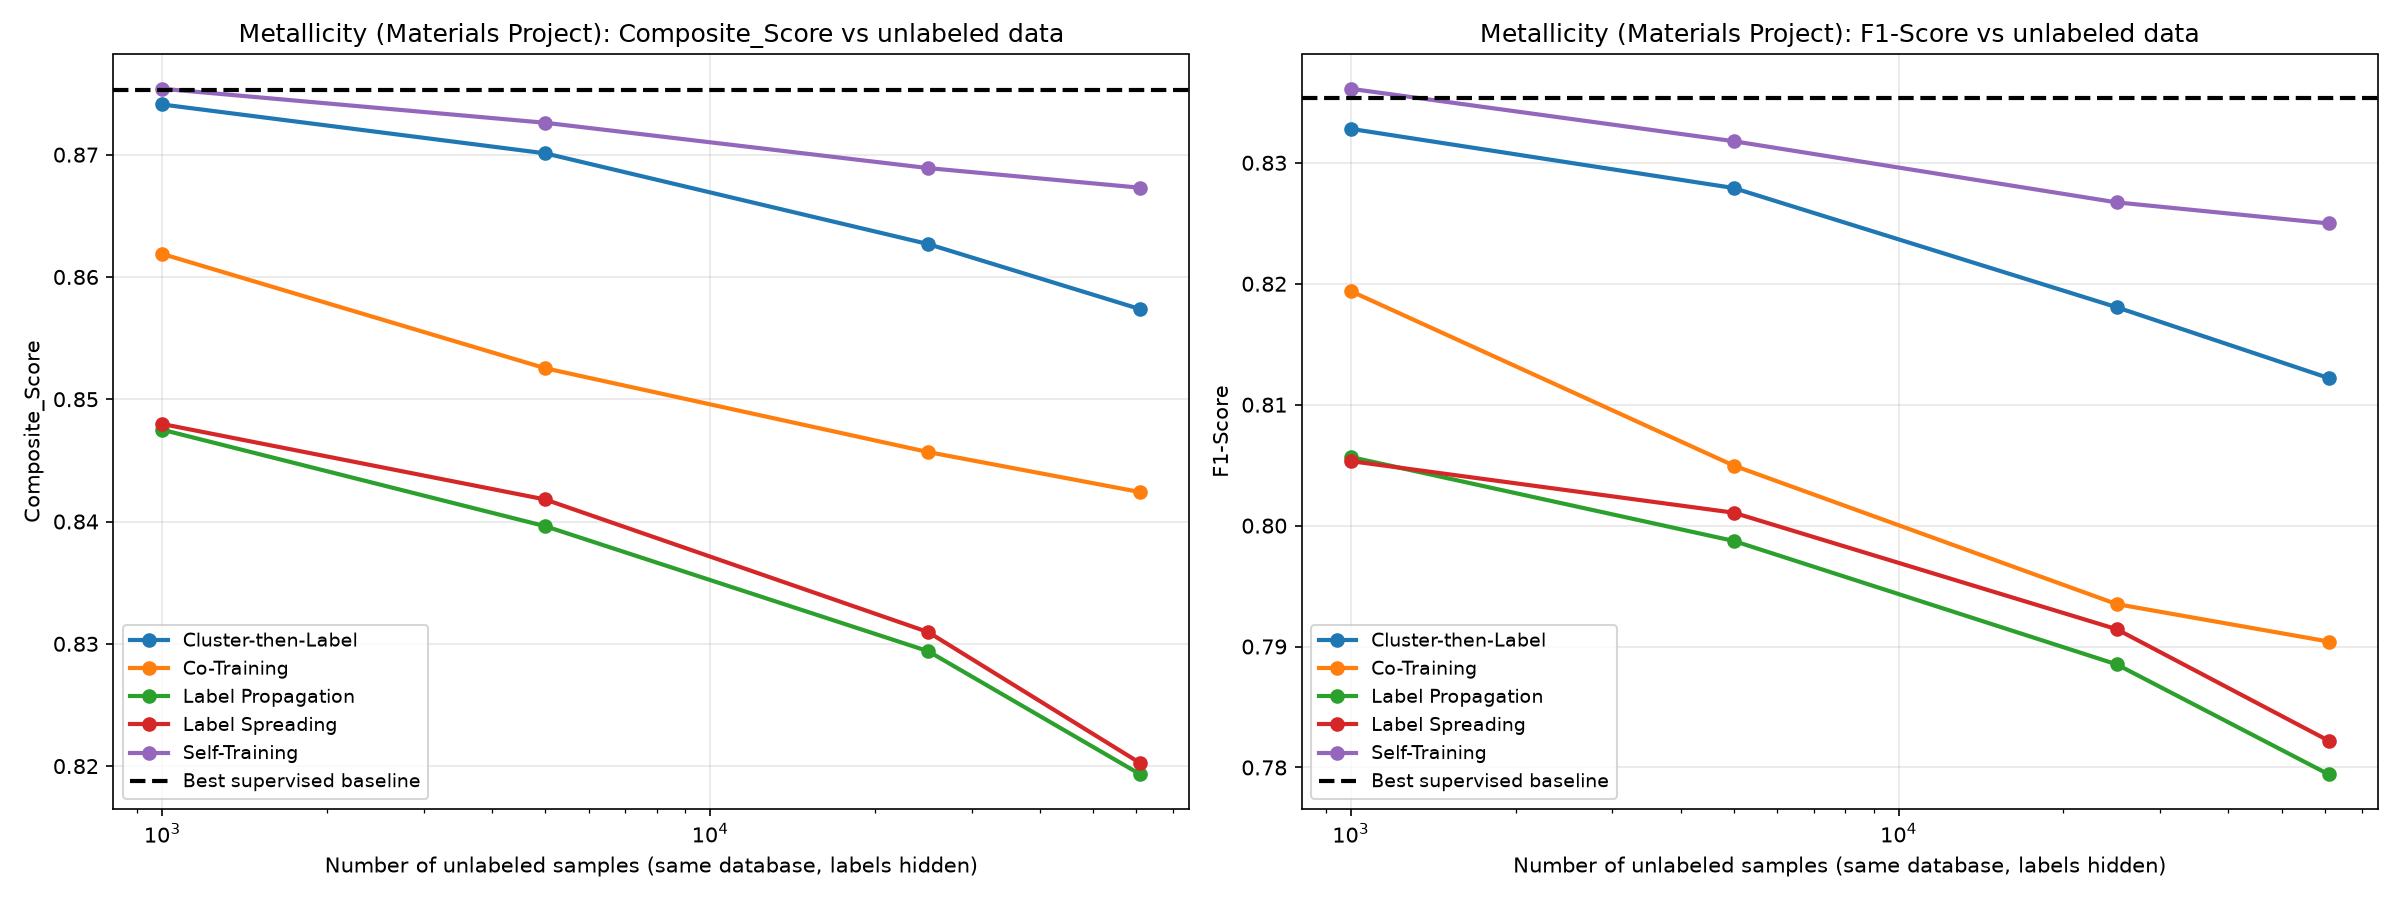

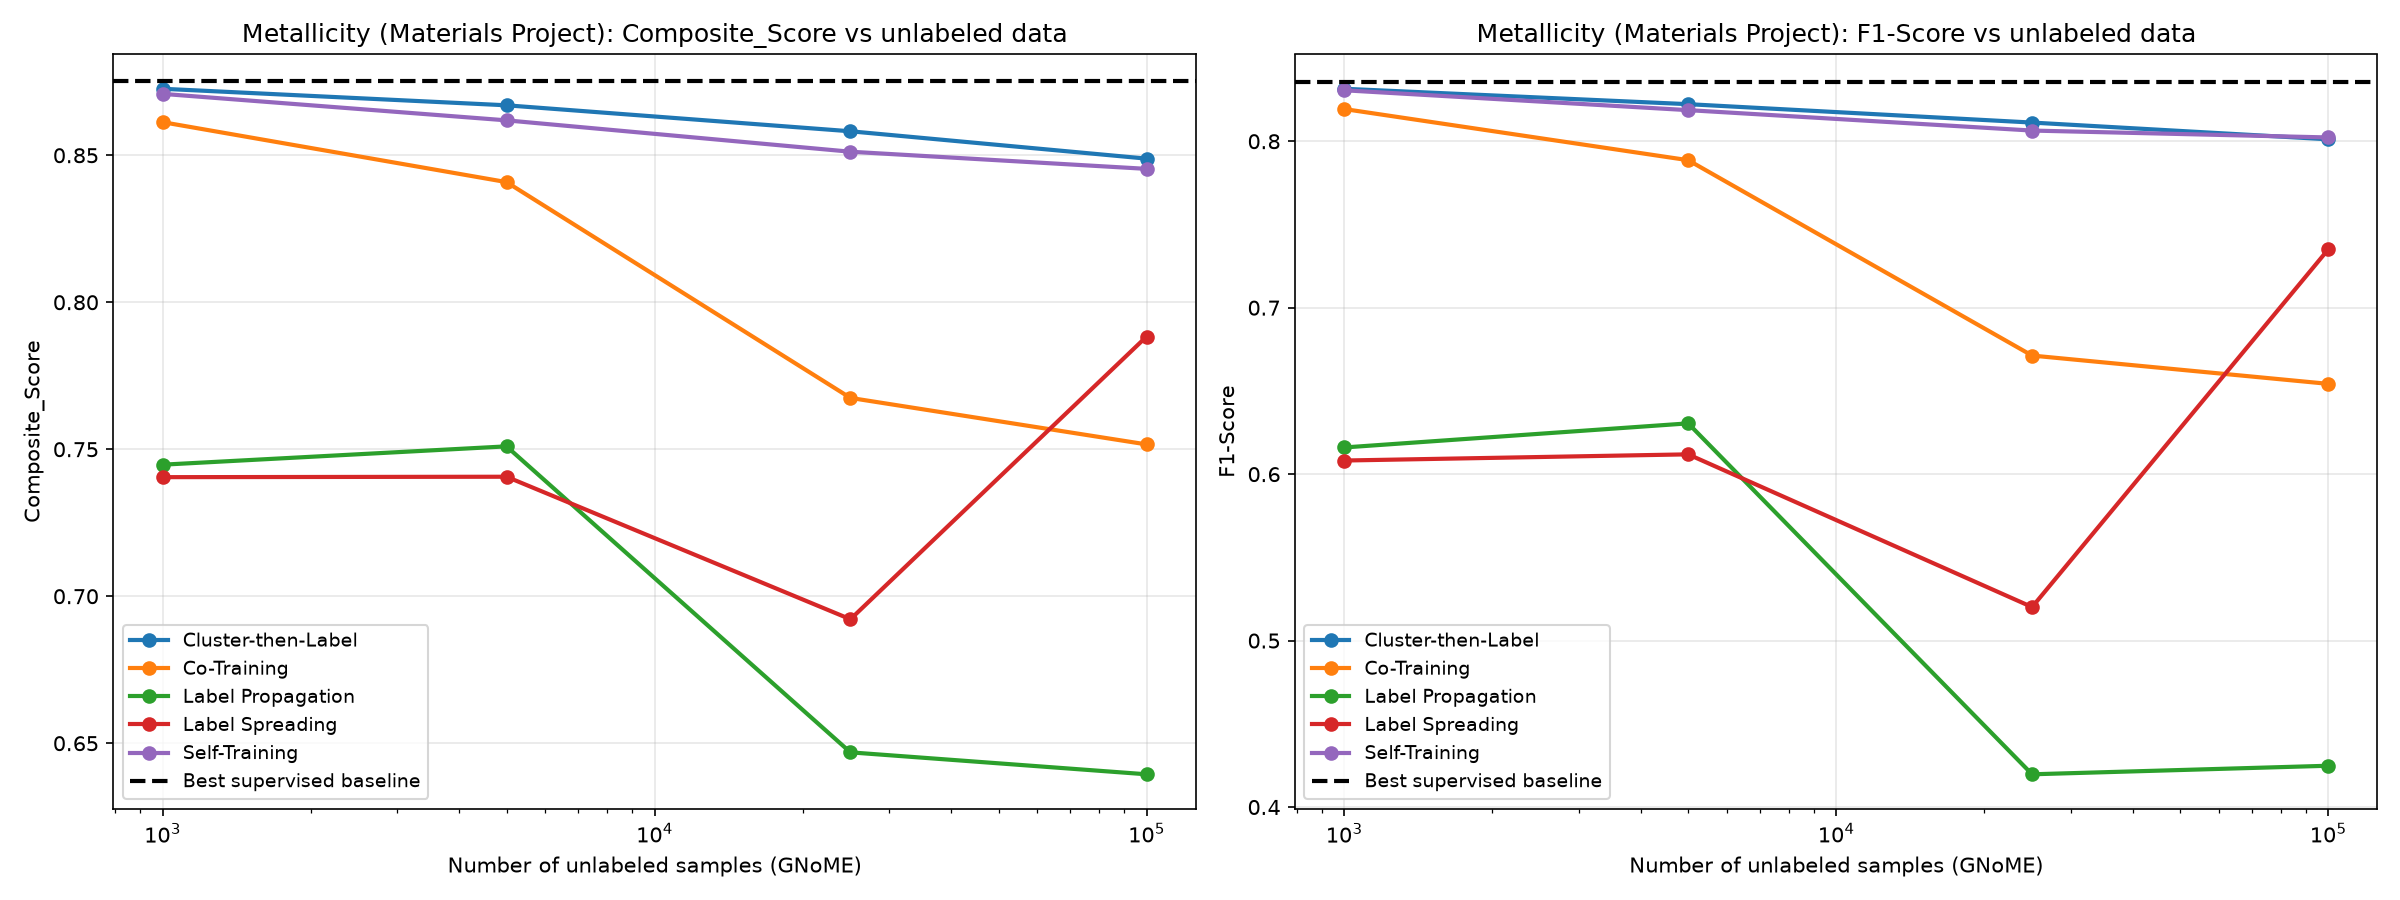

In [8]:
print("STEP 10: LEARNING CURVES")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_learning_curves.png')))

STEP 11: BEST MODELS COMPARISON (balanced composite metric)


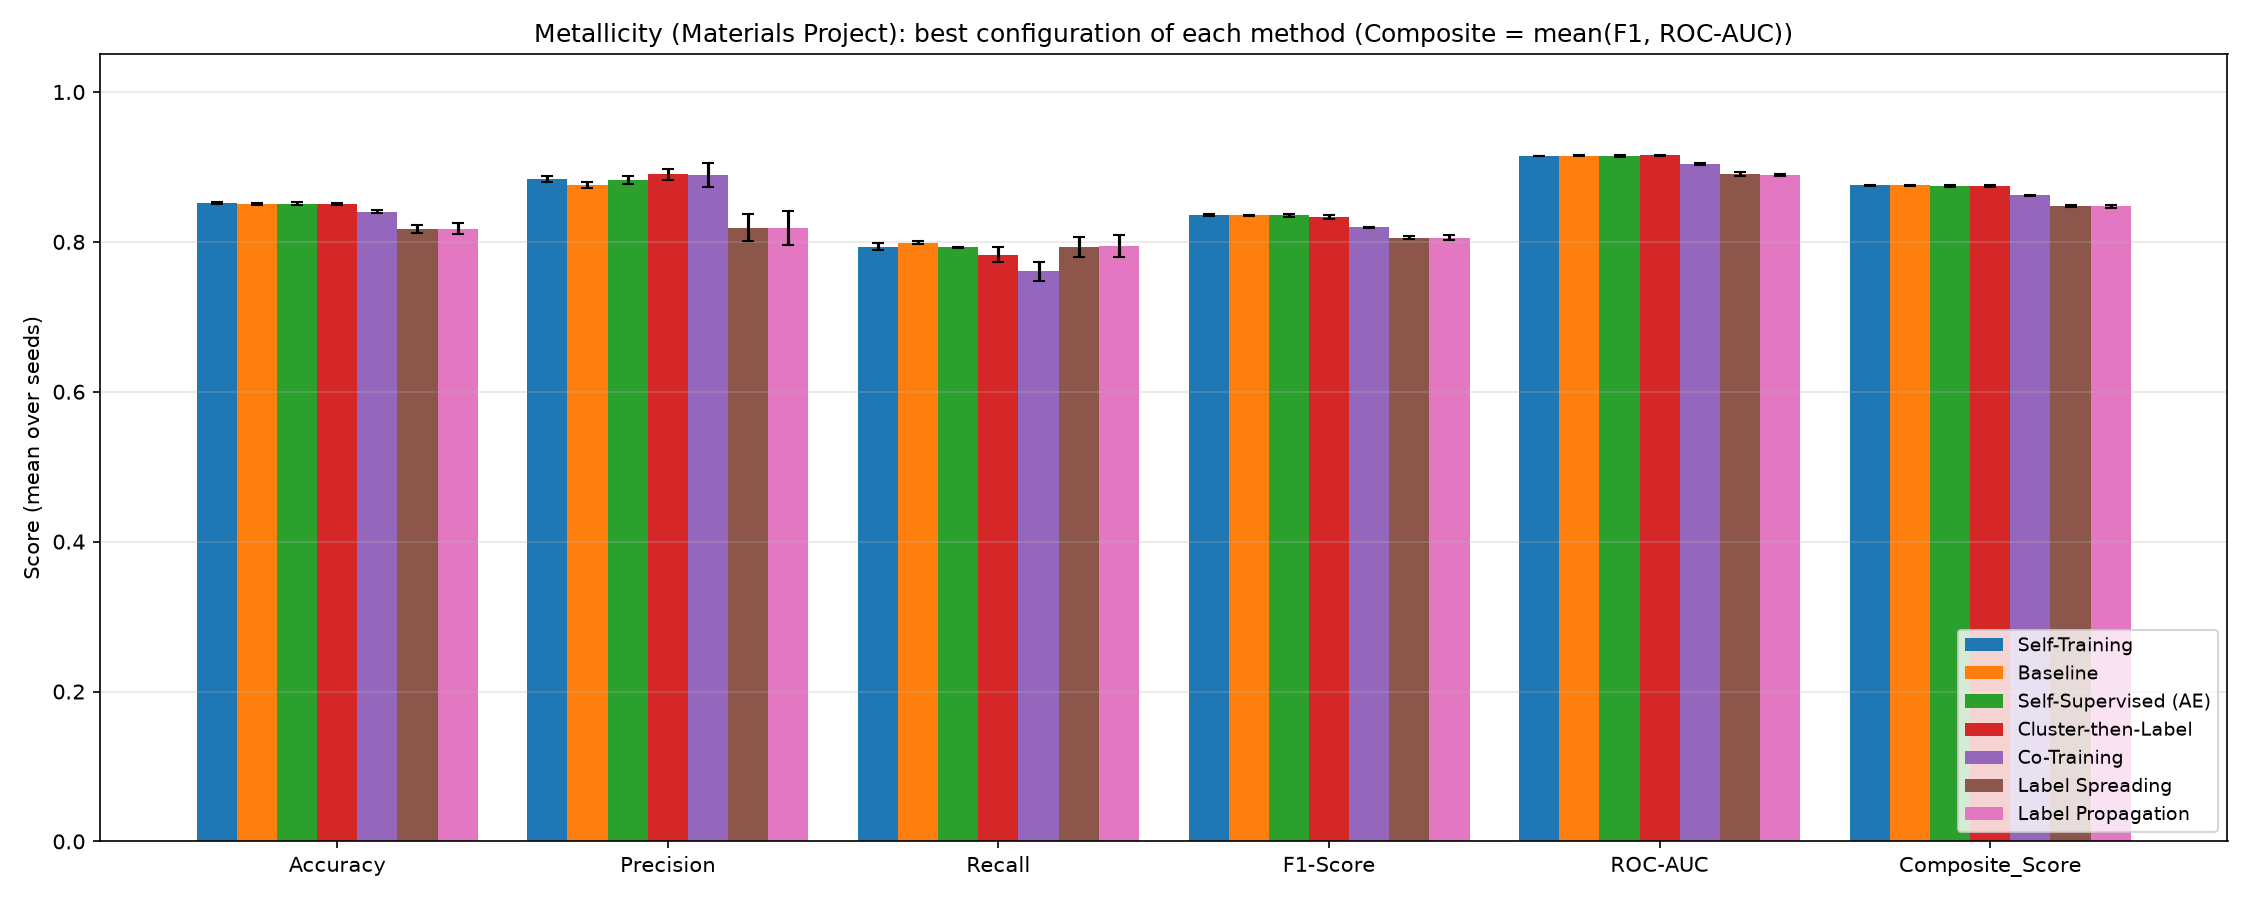

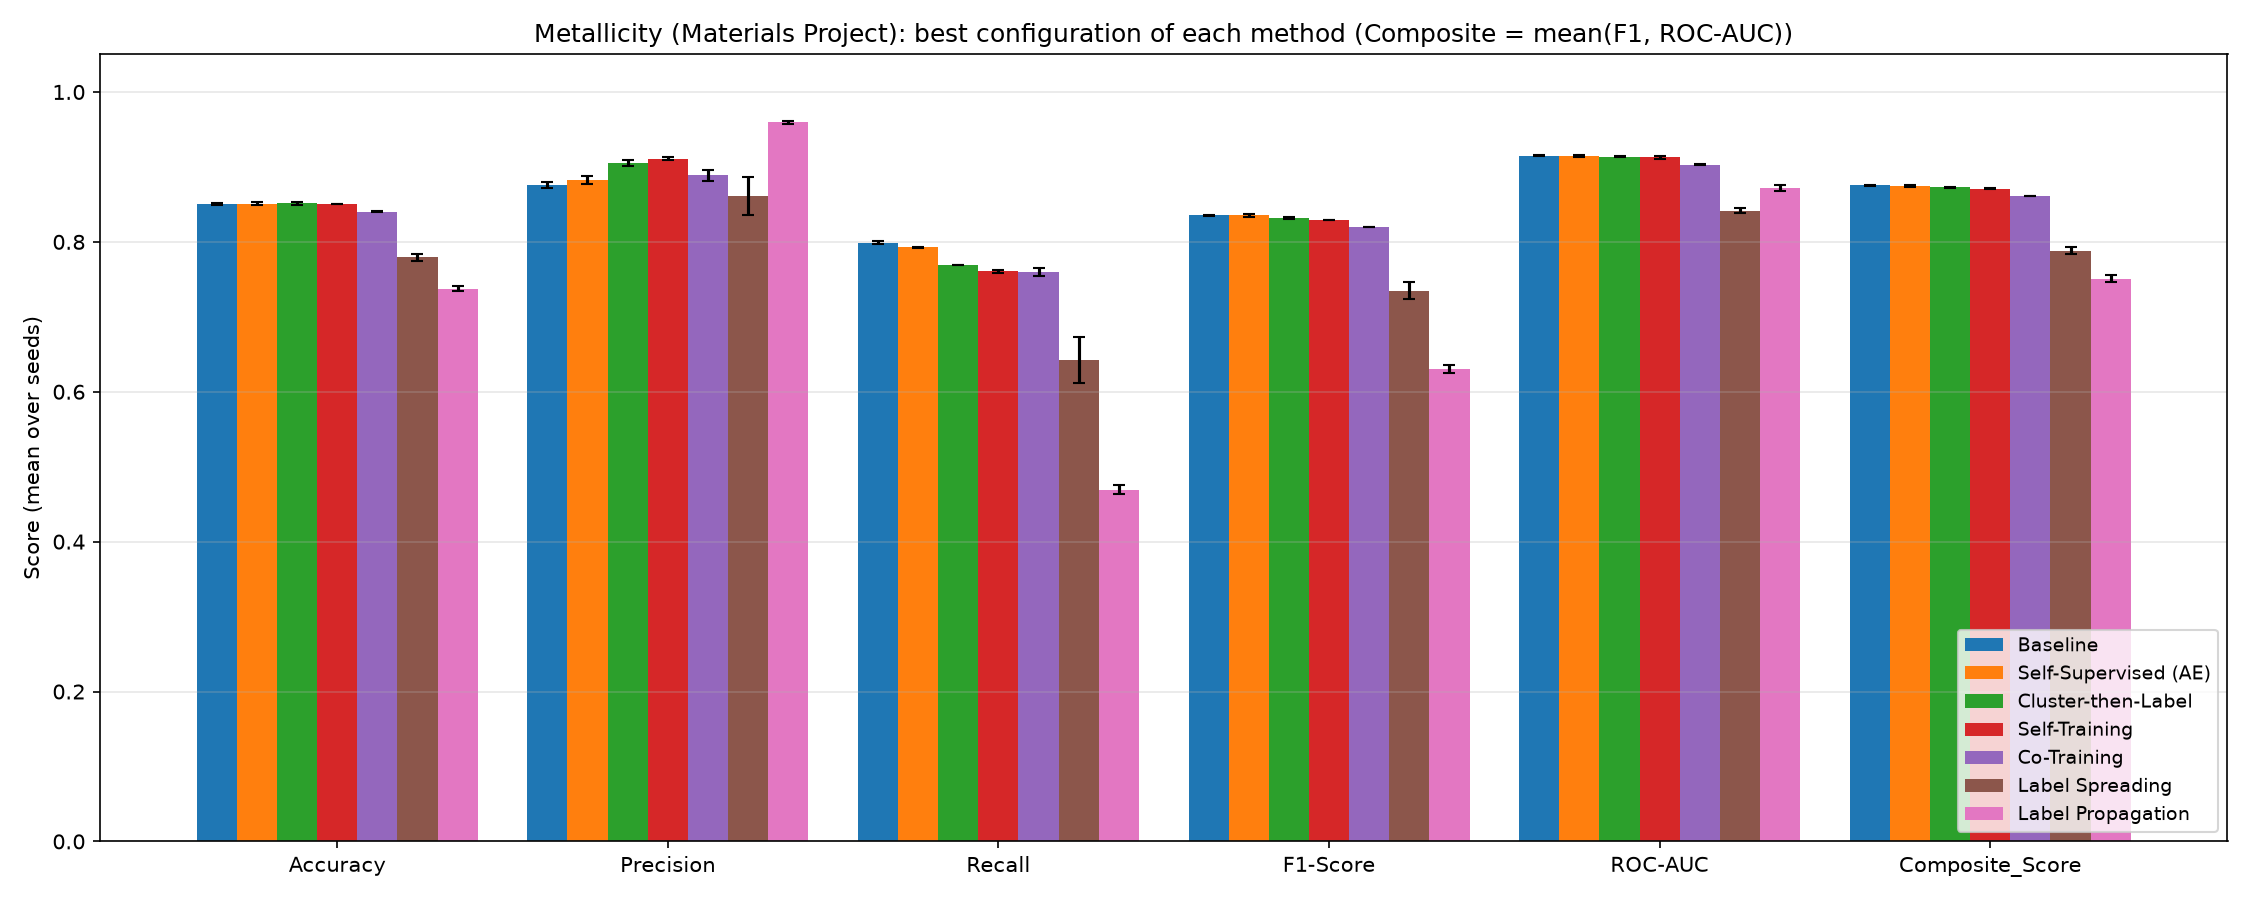

In [9]:
print("STEP 11: BEST MODELS COMPARISON (balanced composite metric)")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_methods_comparison_balanced.png')))

STEP 12: LABEL-BUDGET CURVE AND FULLY-SUPERVISED UPPER BOUND


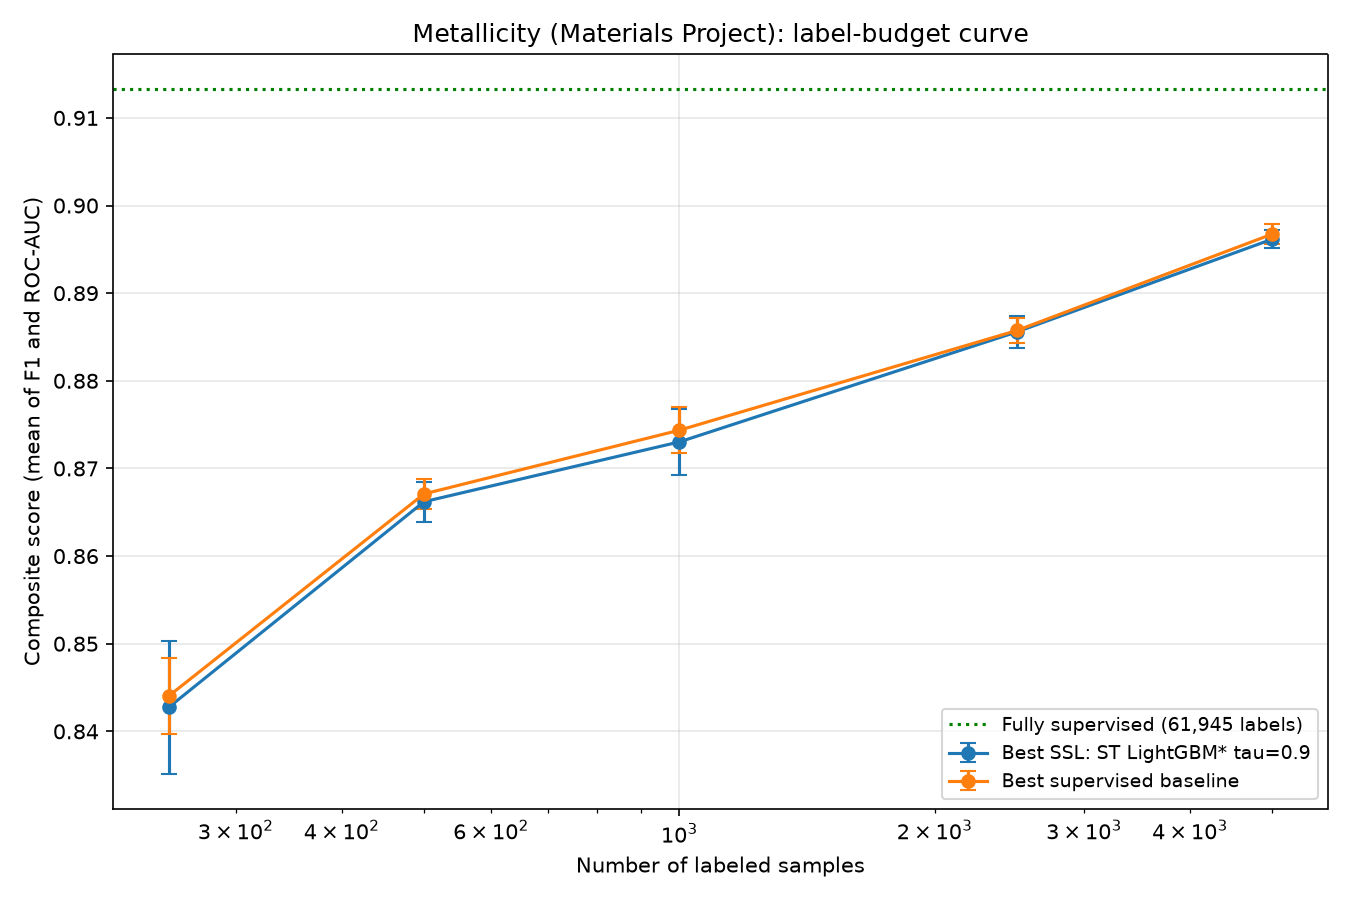

indist fully supervised: {'Composite_Score': 0.9133227939589452, 'F1-Score': 0.8760798753717604, 'ROC-AUC': 0.95056571254613, 'Accuracy': 0.8870020016788274}


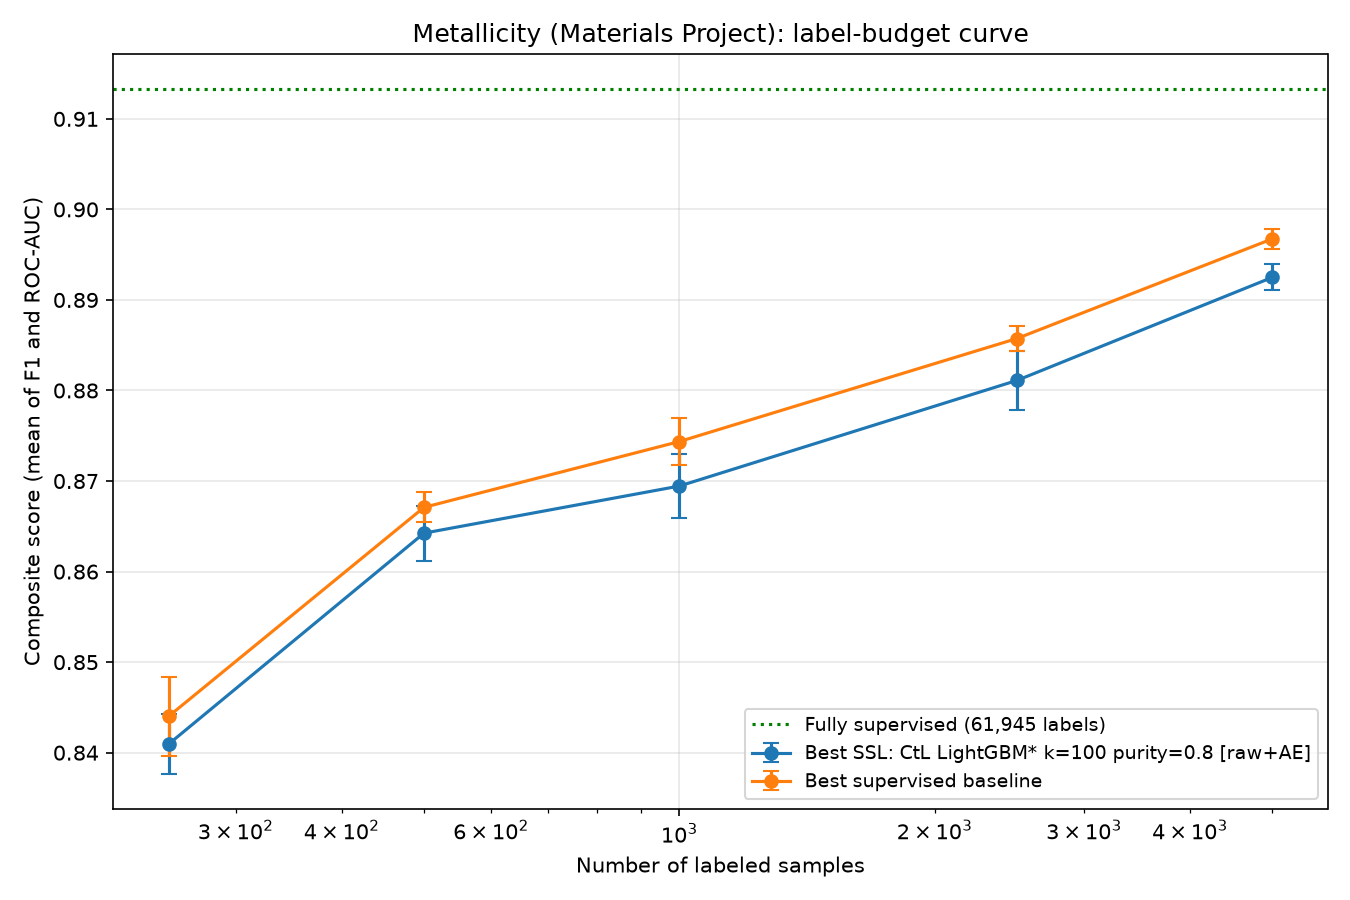

gnome fully supervised: {'Composite_Score': 0.9133227939589452, 'F1-Score': 0.8760798753717604, 'ROC-AUC': 0.95056571254613, 'Accuracy': 0.8870020016788274}


In [10]:
print("STEP 12: LABEL-BUDGET CURVE AND FULLY-SUPERVISED UPPER BOUND")
for p in summ:
    display(Image(str(PRED / p / f'{TASK}_label_budget_curve.png')))
    print(p, 'fully supervised:', summ[p]['fully_supervised_upper_bound'])

### Live run: every method once (seed 0, 1,000 labels, 5,000 unlabeled)

In [11]:
import ssl_core as core
from run_ssl_experiments import Preprocessor, stratified_take
from featurize import view_columns
from sklearn.model_selection import train_test_split
lab = pd.read_parquet(ROOT / 'data/processed' / f'{TASK}_features.parquet')
feat = [c for c in lab.columns if c.startswith(('MagpieData', 'frac ')) or c.endswith('-norm')]
tr, te = train_test_split(np.arange(len(lab)), test_size=0.2, stratify=lab.target, random_state=42)
prep = Preprocessor().fit(lab.iloc[tr][feat])
Xtr, ytr = prep.transform(lab.iloc[tr][feat]), lab.target.values[tr]
Xte, yte = prep.transform(lab.iloc[te][feat]), lab.target.values[te]
rng = np.random.default_rng(0)
li = stratified_take(ytr, 1000, rng)
rest = rng.permutation(np.setdiff1d(np.arange(len(ytr)), li))[:5000]
keep = stratified_take(yte, min(10000, len(yte)), rng)
d = core.Data(Xtr[li], ytr[li], Xtr[rest], Xte[keep], yte[keep])
v1n, v2n = view_columns()
v2 = [i for i, c in enumerate(prep.cols) if c in v2n or (any(k in c for k in ('Valence', 'Unfilled', 'Column', 'Row')) and (c.endswith(' mean') or c.endswith(' avg_dev')))]
v1 = [i for i in range(len(prep.cols)) if i not in v2]
best = summ['indist']['best_supervised_baseline']['config'].split(' ')[0]
params = summ['indist']['tuned_params'].get(best, {})
runs = [core.run_baseline(d, best, params=params)[0],
        core.run_label_propagation(d, 'knn', n_neighbors=10)[0],
        core.run_label_propagation(d, 'knn', n_neighbors=10, spreading=True)[0],
        core.run_self_training(d, best, threshold=0.9, max_iter=5, params=params)[0],
        core.run_co_training(d, v1, v2, best, threshold=0.85, n_rounds=8, params=params)[0],
        core.run_cluster_then_label(d, best, params=params)[0]]
pd.DataFrame(runs)[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Composite_Score', 'Training_Time']].round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Composite_Score,Training_Time
0,Baseline LightGBM (1000 labeled),0.8476,0.8656,0.8053,0.8343,0.9130,0.8737,0.8876
1,"LabelPropagation (knn, k=10, n=5000)",0.8056,0.8050,0.7814,0.7930,0.8783,0.8356,0.8304
2,"LabelSpreading (knn, k=10, alpha=0.2, n=5000)",0.7999,0.7943,0.7828,0.7885,0.8747,0.8316,0.5418
3,"SelfTraining-LightGBM (tau=0.9, n=5000)",0.8496,0.8813,0.7910,0.8337,0.9127,0.8732,5.3477
4,"CoTraining-LightGBM (tau=0.85, n=5000)",0.8356,0.8851,0.7528,0.8136,0.9026,0.8581,12.5316
5,"ClusterThenLabel-LightGBM (k=100, purity=0.8, ...",0.8417,0.8830,0.7698,0.8226,0.9068,0.8647,2.0074


In [12]:
print("STEP 13: DEPLOYED MODEL (selected architecture re-trained on all training labels)")
for p, s in summ.items():
    print(p, s['best_ssl_model']['Model_Config'], '->', s['deployment_model_test_metrics'])

STEP 13: DEPLOYED MODEL (selected architecture re-trained on all training labels)
indist ST LightGBM* tau=0.9 | n=1000 -> {'Composite_Score': 0.9135987665921244, 'F1-Score': 0.8766404199475065, 'ROC-AUC': 0.9505571132367423, 'Accuracy': 0.8877122748111319, 'Precision': 0.9200416914830256, 'Recall': 0.8371494377455629}
gnome CtL LightGBM* k=100 purity=0.8 [raw+AE] | n=1000 -> {'Composite_Score': 0.9125705425282948, 'F1-Score': 0.8750443482580004, 'ROC-AUC': 0.9500967367985893, 'Accuracy': 0.8862917285465229, 'Precision': 0.9186531585220501, 'Recall': 0.8353881587860723}
